Make more implementation using a MLP and feeding more previous letters instead of just 1

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [3]:
words = open('names.txt', 'r').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [ ]:
# since we're building a character level language model we'll have vocabular of only 27 characters
# build vocabulary and mapping from characters to integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i + 1 for i , s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [224]:
# build the dataset
block_size  = 3
X, y = [], []

for w in words:
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        y.append(ix)
        # print(''.join(itos[i] for i in context), '----> ', itos[ix])
        context = context[1:] + [ix]

# X is the tensor of 
X = torch.tensor(X)
y = torch.tensor(y)

In [21]:
# following the paper of Bengio eta 2003
# The main idea is use of  continuous dense feature vectors for words instead of just using their presence before or after a word
# this is the concept of word embeddings, where rather than just one hot encoding a word, we learn the representation of the words in some m
# dimensional space.

# C is embeddings matrix is a |V| x m where  V is the vocabulary size and m is the dimension of the embedding vectors

# lets suppose we use 2 dimensional embeddings to represent the 27 characters then the embeddings matrix will be
C = torch.randn((27, 2))


In [30]:
embs = C[X]

In [50]:
# we currently have a context length of 3, meaning we are using 3 previous tokens to predict the next
# so the embeddings will be of shape n x 3 x 2 where n is the number of examples, 3x2 is shape for 2d embedding for 3 input tokens
# so say we have 100 neurons in the second layer then the weight matrix will be
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [56]:
# we can't just do embs @ W1 + b since, 
# embs.shape = n x 3x 2
# w1.shape = 6 x 100
# but we can do 
# the .view operation is very effecient and fast due to the way pytorch internals work
# we have the stride, size, type of data
# and these parameters are used to quickly view data as different shapes without creating new tensor
# but changing the .view will reflect changes in original tensor

h1 = F.tanh(embs.view((-1, 6)) @ W1 + b1)

In [100]:
# then the last layer which will be a softmax output layer will be of size = 27
# since that is the number of logits

W2 = torch.randn((100, 27))
b2 = torch.randn(27)

logits = (h1 @ W2 + b2)

In [105]:
# negative log likelyhood loss
probs = logits.softmax(dim=1)
loss = -probs[torch.arange(X.shape[0]), y].log().mean()
loss

tensor(15.9553)

In [106]:
print(loss.requires_grad)

False


In [114]:
F.cross_entropy(logits,y )

tensor(18.6879)

In [135]:
# proper setup
g = torch.Generator().manual_seed(322)

C = torch.randn(27,2, generator=g)
W1 = torch.randn(6, 100, generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn(100, 27, generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C ,W1, b1, W2, b2]

In [136]:
for p in parameters:
    p.requires_grad = True
num_params = sum(p.nelement() for p in parameters)
num_params

3481

In [182]:
for i in range(10000):
    # minibatch
    ixs = torch.randint(0, X.shape[0], (32,))
    # forward pass
    embs = C[X[ixs]]
    h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
    logits = h  @ W2 + b2

    # although we can calculate loss as following

    # probs = torch.softmax(logits, dim=1)
    # loss = -probs[torch.arange(X.shape[0]), y].log().mean()

    # directly using the fuctions is much more efficient in backward pass for backpropagatoin and
    # edge cases are also handled, say when a logit goes very high and we may get nan from this from scratch approach

    # loss calculation
    loss = F.cross_entropy(logits, y[ixs])
    if i%1000 == 0:
        print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    for p in parameters:
        p.data -= 0.05 * p.grad


2.3334784507751465
2.518948793411255
2.582188606262207
2.08235502243042
2.201615810394287
2.3692545890808105
2.3820033073425293
2.3787102699279785
2.340672731399536
2.3170149326324463


In [183]:
embs = C[X]
h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
logits = h  @ W2 + b2
loss = F.cross_entropy(logits, y)
loss

tensor(2.3551, grad_fn=<NllLossBackward0>)

Here we see that the loss has ben reduce quite a lot, and we have surpassed the performance of the bigram model (loss for which was 2.46). But here we're training on our entire dataset and hence it might be the case that we're overfitting and if we test the performance on any new unseen list of names, the loss will be high. So to be sure that our model hasn't overfit to the data but also has learned useful generalized information about the structure of names, we witheld some portion of data for just testing purposes and some portion for development puposes like hyperparameter tuning or testing different architectures. 
So we divide datasets in test-dev-train split.

In [225]:
# split data into train dev test
# shuffle the X
l = X.shape[0]
n1 = int(0.8 * l)
n2 = int(0.9 * l)

ix = torch.randperm(l)
X = X[ix]
y = y[ix]

X_train = X[:n1, :]
X_dev = X[n1:n2, :]
X_test = X[n2:,]

y_train = y[:n1]
y_dev = y[n1:n2]
y_test = y[n2:]

In [226]:

# proper setup
g = torch.Generator().manual_seed(322)

C = torch.randn(27,2, generator=g)
W1 = torch.randn(6, 100, generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn(100, 27, generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C ,W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True
num_params = sum(p.nelement() for p in parameters)
num_params

3481

In [230]:
for i in range(10000):
    # minibatch
    ixs = torch.randint(0, X_train.shape[0], (32,))
    # forward pass
    embs = C[X[ixs]]
    h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
    logits = h  @ W2 + b2

    # loss calculation
    loss = F.cross_entropy(logits, y_train[ixs])
    # if i%6000 == 0:
    #     print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # step 
    for p in parameters:
        p.data -= 0.01 * p.grad

print(loss.item())

2.4777944087982178


In [231]:
# calculate loss on the dev set

embs = C[X_dev]
h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
logits = h  @ W2 + b2
loss = F.cross_entropy(logits, y_dev)
loss

tensor(2.3123, grad_fn=<NllLossBackward0>)

In [232]:

embs = C[X_train]
h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
logits = h  @ W2 + b2
loss = F.cross_entropy(logits, y_train)
loss

tensor(2.3102, grad_fn=<NllLossBackward0>)

Here we see that after 50k iterations the devloss and the train loss are almost same.  
We say that we are 'underfitting' and our model is not complex enough and we can' gain performance improvement by increasing the complexity of the network. In other words, we can increase the layers or the number of neurons.  
So lets do that next

In [233]:
# proper setup for 300 neurons
g = torch.Generator().manual_seed(322)

C = torch.randn(27,2, generator=g)
W1 = torch.randn(6, 300, generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn(300, 27, generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C ,W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True
num_params = sum(p.nelement() for p in parameters)
num_params

10281

In [243]:
stepi = []
lossi  = []
for i in range(30000):
    # minibatch
    ixs = torch.randint(0, X_train.shape[0], (32,))
    # forward pass
    embs = C[X[ixs]]
    h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
    logits = h  @ W2 + b2

    # loss calculation
    loss = F.cross_entropy(logits, y_train[ixs])
    # if i%6000 == 0:
    #     print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # step 
    for p in parameters:
        p.data -= 0.01 * p.grad
    
    lossi.append(loss.item())
    stepi.append(i)


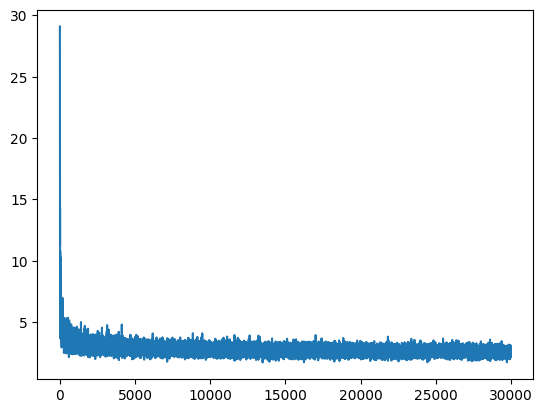

In [235]:
plt.plot(stepi, lossi)

In [253]:

# calculate loss on the dev set

embs = C[X_dev]
h = torch.tanh(embs.view(-1, 6) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
logits = h  @ W2 + b2
loss = F.cross_entropy(logits, y_dev)
loss

tensor(2.2595, grad_fn=<NllLossBackward0>)

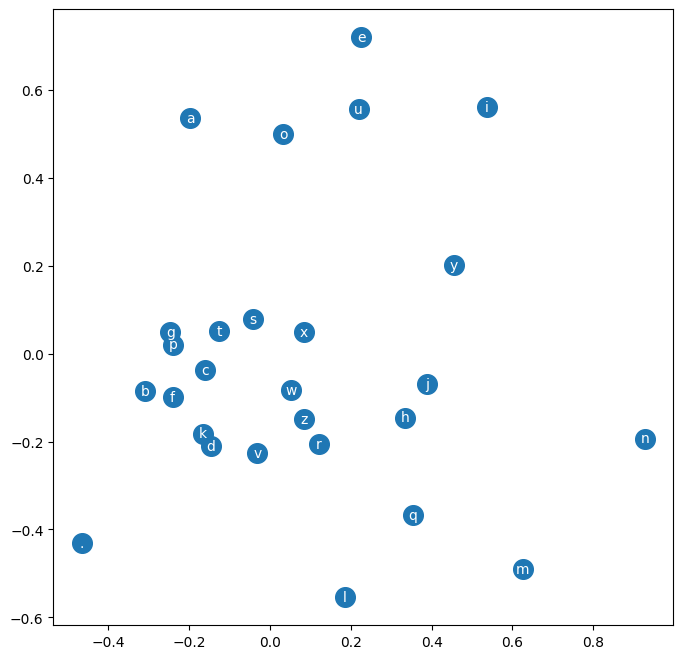

In [ ]:
# visualizing the embeddings in 2d space. 
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha='center', va='center', color='white')

Here the NN has learned to cluster out characters based on the patterns in the name, it has learned that aeiou are somehow related and hence are clustered closer, the . is separete and other consonants are clustered close to zero. 


### Futher improvement to NN
Since we are just using a 2d vector for representing 27 characters, the lower dimension of the embedding might be bottleneck in the models ability to learn and may be it can learn better if we allow the embeddings of higher dimensions, which can be thought of as model learning more different things about the character as opposed to just 2 things in this case. The 'things' here are completely abstract and we can't interpret hey in any way.

In [254]:
# proper setup for 300 neurons and 10 d embeddings
g = torch.Generator().manual_seed(322)

C = torch.randn(27,10, generator=g)
W1 = torch.randn(30, 200, generator=g) # 3 * 10= 30 inputs
b1 = torch.randn(200, generator=g)
W2 = torch.randn(200, 27, generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C ,W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True
num_params = sum(p.nelement() for p in parameters)
num_params

11897

In [255]:
stepi = []
lossi  = []

In [265]:
for i in range(30000):
    # minibatch
    ixs = torch.randint(0, X_train.shape[0], (32,))
    # forward pass
    embs = C[X[ixs]]
    h = torch.tanh(embs.view(-1, 30) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
    logits = h  @ W2 + b2

    # loss calculation
    loss = F.cross_entropy(logits, y_train[ixs])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # step 
    for p in parameters:
        p.data -= 0.01 * p.grad
    
    lossi.append(loss.log10().item())
    stepi.append(i)


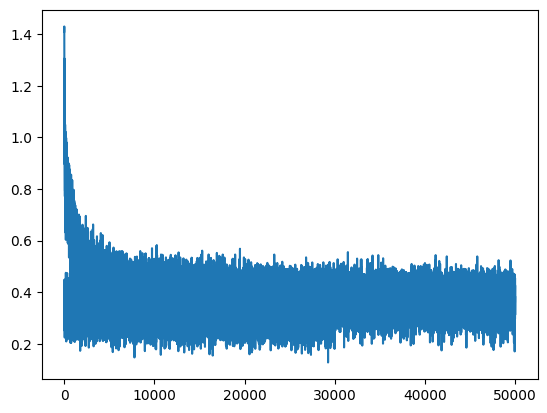

In [266]:
plt.plot(stepi, lossi)

In [267]:
# calculate loss on the dev set

embs = C[X_dev]
h = torch.tanh(embs.view(-1, 30) @ W1 + b1) #here addition works out fine, check for aligment, of the rightmost dimension
logits = h  @ W2 + b2
loss = F.cross_entropy(logits, y_dev)
loss

tensor(2.1905, grad_fn=<NllLossBackward0>)

In [268]:
# calculate loss on the training set
embs = C[X_train]
h = torch.tanh(embs.view(-1, 30) @ W1 + b1)
logits = h  @ W2 + b2
loss = F.cross_entropy(logits, y_train)
loss

tensor(2.1652, grad_fn=<NllLossBackward0>)